# Árbol de Decisión — Detección de fraude (Caso 1)

Se importan las librerías y la configuración compartida desde comun.py.

In [1]:
import sys
sys.path.append("..")

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import GridSearchCV, cross_val_predict
from sklearn.metrics import confusion_matrix, precision_recall_curve, average_precision_score
from comun.comun import (RANDOM_STATE, CV, SCORING, cargar_train, make_prep,
                         guardar, resumen_cv, guardar_resultados)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", "{:,.4f}".format)

Se carga el conjunto de entrenamiento con las 15 predictoras finales.

In [2]:
X, y = cargar_train()
print(f"X: {X.shape[0]:,} filas x {X.shape[1]} predictoras | fraudes: {y.sum()} ({y.mean()*100:.3f}%)")

X: 40,000 filas x 15 predictoras | fraudes: 727 (1.818%)


## 1. Pipeline

Se arma el pipeline con One-Hot para las categóricas, sin escalado porque el árbol no lo necesita, y un Árbol de Decisión con pesos balanceados para compensar el desbalance de clases.

In [3]:
pipe = Pipeline([
    ("prep", make_prep(escalar=False)),
    ("modelo", DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE)),
])
pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{tra

## 2. Validación cruzada y ajuste de hiperparámetros

Se buscan la profundidad máxima y el mínimo de transacciones por hoja con validación cruzada estratificada de 5 folds sobre train, registrando también el rendimiento en entrenamiento para detectar sobreajuste.

In [4]:
grid = GridSearchCV(pipe, {"modelo__max_depth": [3, 4, 5, 6, 8, 10, 15, None],
                           "modelo__min_samples_leaf": [1, 20, 50, 100, 200, 400]},
                    cv=CV, scoring=SCORING, refit="pr_auc", return_train_score=True, n_jobs=-1)
grid.fit(X, y)
print(f"Mejores parámetros: {grid.best_params_} | PR-AUC CV: {grid.best_score_:.4f}")

Mejores parámetros: {'modelo__max_depth': 6, 'modelo__min_samples_leaf': 100} | PR-AUC CV: 0.0348


Se muestran las 10 mejores combinaciones según PR-AUC, comparando el rendimiento en entrenamiento y en validación.

In [5]:
cvr = pd.DataFrame(grid.cv_results_)
(cvr.assign(max_depth=cvr["param_modelo__max_depth"].astype(str),
            min_samples_leaf=cvr["param_modelo__min_samples_leaf"])
    .set_index(["max_depth", "min_samples_leaf"])
    [["mean_train_pr_auc", "mean_test_pr_auc", "mean_test_roc_auc", "mean_test_recall", "mean_test_precision"]]
    .rename(columns=lambda c: c.replace("mean_", "").replace("test_", "val_"))
    .sort_values("val_pr_auc", ascending=False).head(10))

train_pr_auc  val_pr_auc  val_roc_auc  val_recall  \
max_depth min_samples_leaf                                                      
6         100                     0.0629      0.0348       0.6311      0.4966   
          200                     0.0544      0.0341       0.6461      0.5572   
4         200                     0.0450      0.0339       0.6613      0.5133   
          400                     0.0419      0.0337       0.6570      0.5380   
5         100                     0.0551      0.0337       0.6391      0.5364   
          400                     0.0447      0.0336       0.6487      0.5297   
4         100                     0.0466      0.0336       0.6555      0.5270   
5         200                     0.0503      0.0334       0.6469      0.5530   
8         20                      0.1004      0.0333       0.5747      0.4511   
6         50                      0.0675      0.0331       0.6152      0.4967   

                            val_precision  
max_depth min_samples_leaf                 
6         100                      0.0307  
          200                      0.0325  
4         200                      0.0331  
          400                      0.0330  
5         100                      0.0327  
          400                      0.0312  
4         100                      0.0317  
5         200                      0.0321  
8         20                       0.0272  
6         50                       0.0305

Se resumen las métricas del mejor árbol como media y desviación estándar de los 5 folds.

In [6]:
resumen = resumen_cv(grid)
resumen

,media,std
métrica,,
precision,0.0307,0.0036
recall,0.4966,0.0455
f1,0.0578,0.0066
roc_auc,0.6311,0.0230
pr_auc,0.0348,0.0054


## 3. Predicciones fuera de fold

Se obtienen probabilidades fuera de fold sobre train para construir la matriz de confusión sin tocar el test.

In [7]:
oof = cross_val_predict(grid.best_estimator_, X, y, cv=CV, method="predict_proba", n_jobs=-1)[:, 1]
pred = (oof >= 0.5).astype(int)
print(f"Probabilidades fuera de fold: {len(oof):,} | valores distintos: {np.unique(oof).size} | "
      f"predichas como fraude con umbral 0.5: {pred.sum():,}")

Probabilidades fuera de fold: 40,000 | valores distintos: 184 | predichas como fraude con umbral 0.5: 11,866


Se grafica la matriz de confusión fuera de fold con umbral 0.5.

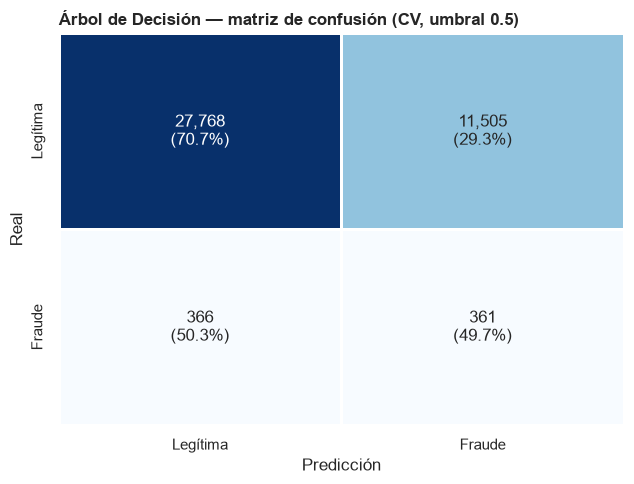

In [8]:
cm = confusion_matrix(y, pred)
etiquetas = np.array([[f"{v:,}\n({v / fila.sum() * 100:.1f}%)" for v in fila] for fila in cm])
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(cm, annot=etiquetas, fmt="", cmap="Blues", cbar=False, linewidths=1,
            xticklabels=["Legítima", "Fraude"], yticklabels=["Legítima", "Fraude"], ax=ax)
ax.set(xlabel="Predicción", ylabel="Real")
ax.set_title("Árbol de Decisión — matriz de confusión (CV, umbral 0.5)", loc="left", fontweight="bold")
guardar("arbol_matriz_confusion")

Se presenta la matriz de confusión en formato de tabla con los conteos de cada caso.

In [9]:
pd.DataFrame(cm, index=pd.Index(["Legítima", "Fraude"], name="Real"),
             columns=pd.Index(["Legítima", "Fraude"], name="Predicción"))

Predicción,Legítima,Fraude
Real,,
Legítima,27768,11505
Fraude,366,361


Se calculan la precisión, la sensibilidad (recall) y el F1-score de la clase fraude con umbral 0.5.

In [10]:
tn, fp, fn, tp = cm.ravel()
pd.DataFrame({"valor": {"Precision = VP / (VP + FP)": tp / (tp + fp),
                        "Sensibilidad (Recall) = VP / (VP + FN)": tp / (tp + fn),
                        "F1-score = 2·VP / (2·VP + FP + FN)": 2 * tp / (2 * tp + fp + fn)}})

,valor
Precision = VP / (VP + FP),0.0304
Sensibilidad (Recall) = VP / (VP + FN),0.4966
F1-score = 2·VP / (2·VP + FP + FN),0.0573


## 4. Curva Precision-Recall y capacidad de revisión

Se grafica la curva Precision-Recall fuera de fold frente a la línea base de un clasificador aleatorio, marcando el umbral 0.5.

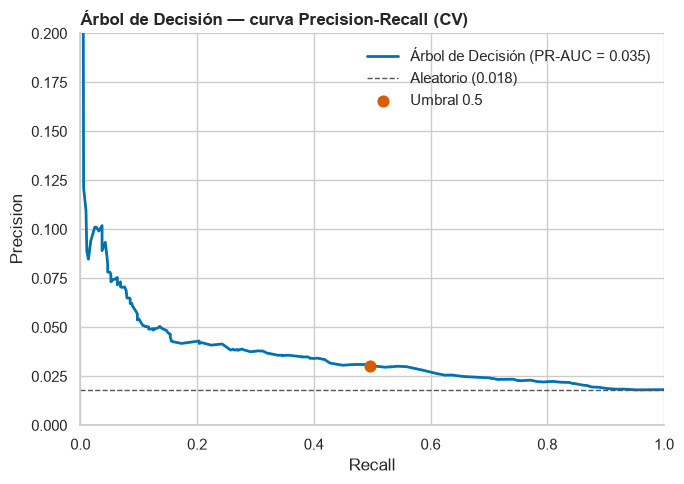

In [11]:
prec, rec, umb = precision_recall_curve(y, oof)
i05 = np.searchsorted(umb, 0.5)

fig, ax = plt.subplots(figsize=(7, 5))
sns.lineplot(x=rec, y=prec, estimator=None, sort=False, color="#0072B2", lw=2,
             label=f"Árbol de Decisión (PR-AUC = {average_precision_score(y, oof):.3f})", ax=ax)
ax.axhline(y.mean(), ls="--", color="#555", lw=1, label=f"Aleatorio ({y.mean():.3f})")
ax.scatter(rec[i05], prec[i05], color="#D55E00", s=60, zorder=3, label="Umbral 0.5")
ax.set(xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 0.2))
ax.set_title("Árbol de Decisión — curva Precision-Recall (CV)", loc="left", fontweight="bold")
ax.legend(frameon=False)
sns.despine()
guardar("arbol_curva_pr")

Se calcula cuántos fraudes se detectarían si el equipo antifraude revisara solo el porcentaje de transacciones con mayor probabilidad de fraude.

In [12]:
yv = y.values
filas = []
for pct in [1, 2, 5, 10, 20, 30]:
    u = np.quantile(oof, 1 - pct / 100)
    alerta = oof >= u
    tp = (alerta & (yv == 1)).sum()
    filas.append({"% objetivo": pct, "umbral": u, "alertas": alerta.sum(), "% real": alerta.mean() * 100,
                  "fraudes detectados": tp, "recall": tp / yv.sum(), "precision": tp / alerta.sum()})
pd.DataFrame(filas).set_index("% objetivo")

,umbral,alertas,% real,fraudes detectados,recall,precision
% objetivo,,,,,,
1,0.8701,414,1.0350,34,0.0468,0.0821
2,0.8283,829,2.0725,57,0.0784,0.0688
5,0.7514,2002,5.0050,100,0.1376,0.0500
10,0.6890,4245,10.6125,176,0.2421,0.0415
20,0.5993,8051,20.1275,281,0.3865,0.0349
30,0.4971,12109,30.2725,366,0.5034,0.0302


## 5. Reglas del árbol y variables más influyentes

Se dibujan los tres primeros niveles del árbol final para mostrar sus reglas de decisión (las proporciones de clase están ponderadas por class_weight).

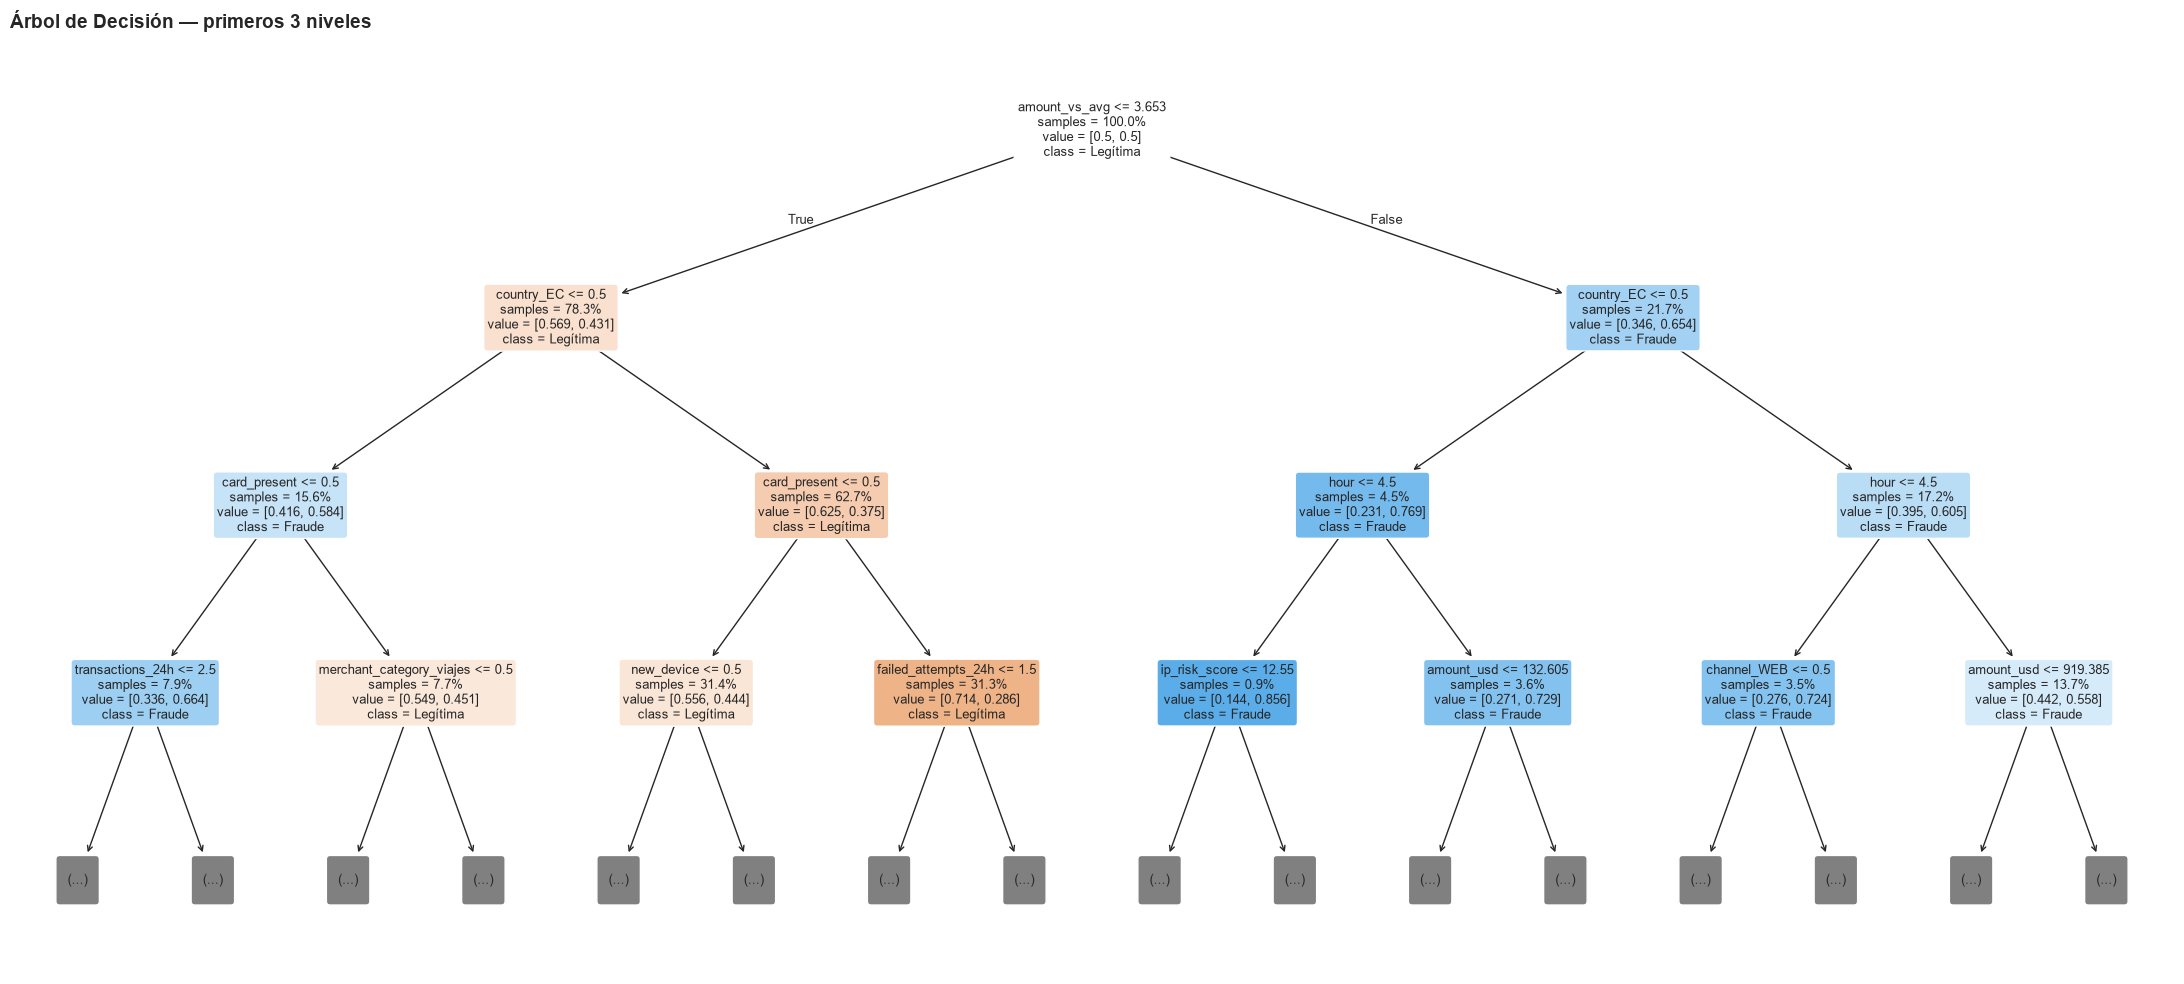

In [13]:
modelo = grid.best_estimator_
nombres = modelo.named_steps["prep"].get_feature_names_out()
fig, ax = plt.subplots(figsize=(22, 10))
plot_tree(modelo.named_steps["modelo"], feature_names=nombres, class_names=["Legítima", "Fraude"],
          max_depth=3, filled=True, rounded=True, impurity=False, proportion=True, fontsize=9, ax=ax)
ax.set_title("Árbol de Decisión — primeros 3 niveles", loc="left", fontsize=14, fontweight="bold")
guardar("arbol_reglas")

Se presentan las mismas reglas en formato de texto.

In [14]:
from sklearn.tree import export_text

print(export_text(modelo.named_steps["modelo"], feature_names=list(nombres), max_depth=3))

|--- amount_vs_avg <= 3.65
|   |--- country_EC <= 0.50
|   |   |--- card_present <= 0.50
|   |   |   |--- transactions_24h <= 2.50
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- transactions_24h >  2.50
|   |   |   |   |--- truncated branch of depth 3
|   |   |--- card_present >  0.50
|   |   |   |--- merchant_category_viajes <= 0.50
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- merchant_category_viajes >  0.50
|   |   |   |   |--- class: 1
|   |--- country_EC >  0.50
|   |   |--- card_present <= 0.50
|   |   |   |--- new_device <= 0.50
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- new_device >  0.50
|   |   |   |   |--- truncated branch of depth 3
|   |   |--- card_present >  0.50
|   |   |   |--- failed_attempts_24h <= 1.50
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- failed_attempts_24h >  1.50
|   |   |   |   |--- truncated branch of depth 3
|--- amount_vs_avg >  3.65
|   |--- country_EC <= 0.50
|   |  

Se grafica la importancia de cada variable en el árbol, medida como la reducción de impureza que aporta en sus cortes.

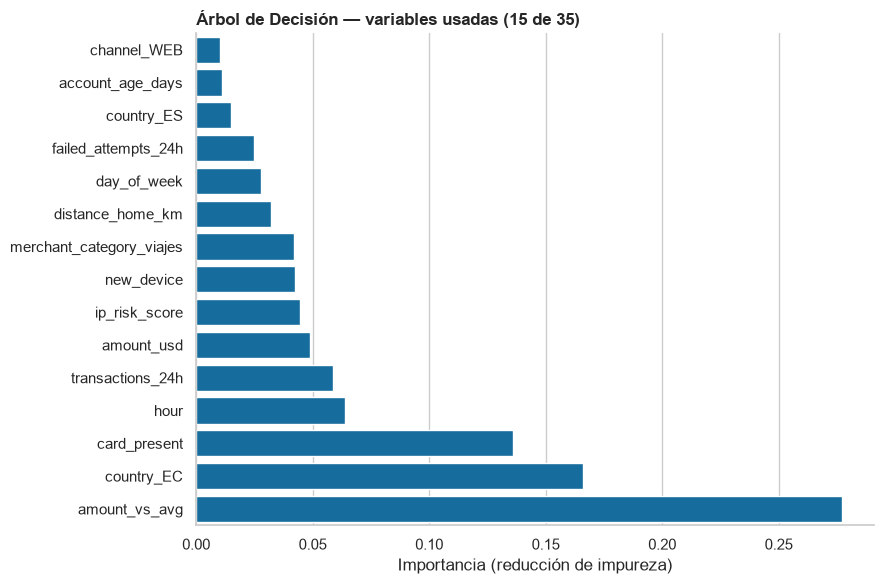

In [15]:
imp = pd.Series(modelo.named_steps["modelo"].feature_importances_, index=nombres).sort_values(ascending=False)
top = imp[imp > 0].head(15).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(x=top.values, y=top.index, color="#0072B2", ax=ax)
ax.set(xlabel="Importancia (reducción de impureza)", ylabel="")
ax.set_title(f"Árbol de Decisión — variables usadas ({(imp > 0).sum()} de {len(imp)})", loc="left", fontweight="bold")
sns.despine()
guardar("arbol_importancia")

## 6. Versión mejorada

Se reajusta el árbol con un peso de fraude menor (×10 en lugar de balanced, que corta sobre ruido) y profundidades bajas; los experimentos previos mostraron que el criterio (gini/entropy), la poda ccp_alpha, max_leaf_nodes y SMOTE no mejoran, por lo que se fijan gini y sin poda.

In [16]:
grid_v2 = GridSearchCV(pipe, {"modelo__max_depth": [3, 4, 5, 6],
                              "modelo__min_samples_leaf": [25, 50, 100],
                              "modelo__class_weight": ["balanced", {0: 1, 1: 10}]},
                       cv=CV, scoring=SCORING, refit="pr_auc", return_train_score=True, n_jobs=-1)
grid_v2.fit(X, y)
print(f"Mejores parámetros: {grid_v2.best_params_} | PR-AUC CV: {grid_v2.best_score_:.4f}")

Mejores parámetros: {'modelo__class_weight': {0: 1, 1: 10}, 'modelo__max_depth': 4, 'modelo__min_samples_leaf': 50} | PR-AUC CV: 0.0397


Se muestran las 8 mejores combinaciones con su PR-AUC en entrenamiento y validación y el cociente entre ambos como medida de sobreajuste.

In [17]:
cv2 = pd.DataFrame(grid_v2.cv_results_)
(cv2.assign(peso=cv2["param_modelo__class_weight"].astype(str),
            max_depth=cv2["param_modelo__max_depth"], min_samples_leaf=cv2["param_modelo__min_samples_leaf"],
            sobreajuste=cv2["mean_train_pr_auc"] / cv2["mean_test_pr_auc"])
    .set_index(["peso", "max_depth", "min_samples_leaf"])
    [["mean_train_pr_auc", "mean_test_pr_auc", "std_test_pr_auc", "sobreajuste", "mean_test_roc_auc"]]
    .rename(columns=lambda c: c.replace("mean_", "").replace("test_", "val_"))
    .sort_values("val_pr_auc", ascending=False).head(8))

train_pr_auc  val_pr_auc  \
peso          max_depth min_samples_leaf                             
{0: 1, 1: 10} 4         50                      0.0508      0.0397   
                        100                     0.0477      0.0384   
                        25                      0.0512      0.0381   
              5         100                     0.0567      0.0376   
                        50                      0.0636      0.0374   
                        25                      0.0669      0.0369   
              6         25                      0.0853      0.0364   
                        100                     0.0626      0.0356   

                                          std_val_pr_auc  sobreajuste  \
peso          max_depth min_samples_leaf                                
{0: 1, 1: 10} 4         50                        0.0054       1.2791   
                        100                       0.0053       1.2412   
                        25                        0.0052       1.3442   
              5         100                       0.0043       1.5089   
                        50                        0.0045       1.7013   
                        25                        0.0058       1.8135   
              6         25                        0.0061       2.3400   
                        100                       0.0038       1.7611   

                                          val_roc_auc  
peso          max_depth min_samples_leaf               
{0: 1, 1: 10} 4         50                     0.6718  
                        100                    0.6730  
                        25                     0.6712  
              5         100                    0.6643  
                        50                     0.6587  
                        25                     0.6575  
              6         25                     0.6338  
                        100                    0.6479

Se comparan las métricas de CV del árbol base y del árbol mejorado.

In [18]:
pd.concat({"base": resumen_cv(grid), "mejorado": resumen_cv(grid_v2)}, axis=1)

base        mejorado       
           media    std    media    std
métrica                                
precision 0.0307 0.0036   0.0788 0.0193
recall    0.4966 0.0455   0.0592 0.0234
f1        0.0578 0.0066   0.0656 0.0199
roc_auc   0.6311 0.0230   0.6718 0.0239
pr_auc    0.0348 0.0054   0.0397 0.0054

Se obtienen las probabilidades fuera de fold del árbol mejorado y se elige el umbral que maximiza F1.

In [19]:
oof_v2 = cross_val_predict(grid_v2.best_estimator_, X, y, cv=CV, method="predict_proba", n_jobs=-1)[:, 1]
p2, r2, u2 = precision_recall_curve(y, oof_v2)
f1 = 2 * p2 * r2 / (p2 + r2 + 1e-12)
k = f1[:-1].argmax()
umbral = u2[k]
print(f"Valores distintos de probabilidad: {np.unique(oof_v2).size} | Umbral óptimo F1: {umbral:.3f} | "
      f"alertas: {(oof_v2 >= umbral).mean()*100:.1f}% de las transacciones")

Valores distintos de probabilidad: 78 | Umbral óptimo F1: 0.343 | alertas: 2.8% de las transacciones


Se presenta la matriz de confusión fuera de fold del árbol mejorado con el umbral óptimo de F1.

In [20]:
cm2 = confusion_matrix(y, (oof_v2 >= umbral).astype(int))
pd.DataFrame(cm2, index=pd.Index(["Legítima", "Fraude"], name="Real"),
             columns=pd.Index(["Legítima", "Fraude"], name="Predicción"))

Predicción,Legítima,Fraude
Real,,
Legítima,38254,1019
Fraude,640,87


Se calculan la precisión, la sensibilidad (recall) y el F1-score del árbol mejorado con el umbral óptimo.

In [21]:
tn, fp, fn, tp = cm2.ravel()
pd.DataFrame({"valor": {"Umbral": umbral,
                        "Precision = VP / (VP + FP)": tp / (tp + fp),
                        "Sensibilidad (Recall) = VP / (VP + FN)": tp / (tp + fn),
                        "F1-score = 2·VP / (2·VP + FP + FN)": 2 * tp / (2 * tp + fp + fn)}})

,valor
Umbral,0.3427
Precision = VP / (VP + FP),0.0787
Sensibilidad (Recall) = VP / (VP + FN),0.1197
F1-score = 2·VP / (2·VP + FP + FN),0.0949


Se calcula cuántos fraudes detectaría el árbol mejorado si el equipo antifraude revisara solo el porcentaje de transacciones de mayor riesgo.

In [22]:
filas = []
for pct in [1, 2, 5, 10, 20, 30]:
    u = np.quantile(oof_v2, 1 - pct / 100)
    alerta = oof_v2 >= u
    tp_ = (alerta & (yv == 1)).sum()
    filas.append({"% objetivo": pct, "umbral": u, "% real": alerta.mean() * 100,
                  "fraudes detectados": tp_, "recall": tp_ / yv.sum(), "precision": tp_ / alerta.sum()})
pd.DataFrame(filas).set_index("% objetivo")

,umbral,% real,fraudes detectados,recall,precision
% objetivo,,,,,
1,0.5195,1.0225,29,0.0399,0.0709
2,0.4167,2.0650,72,0.0990,0.0872
5,0.2857,5.3975,126,0.1733,0.0584
10,0.2674,10.9450,185,0.2545,0.0423
20,0.2096,20.3625,310,0.4264,0.0381
30,0.1754,31.5950,417,0.5736,0.0330


Se dibuja el árbol mejorado completo (profundidad 4) con sus reglas de decisión.

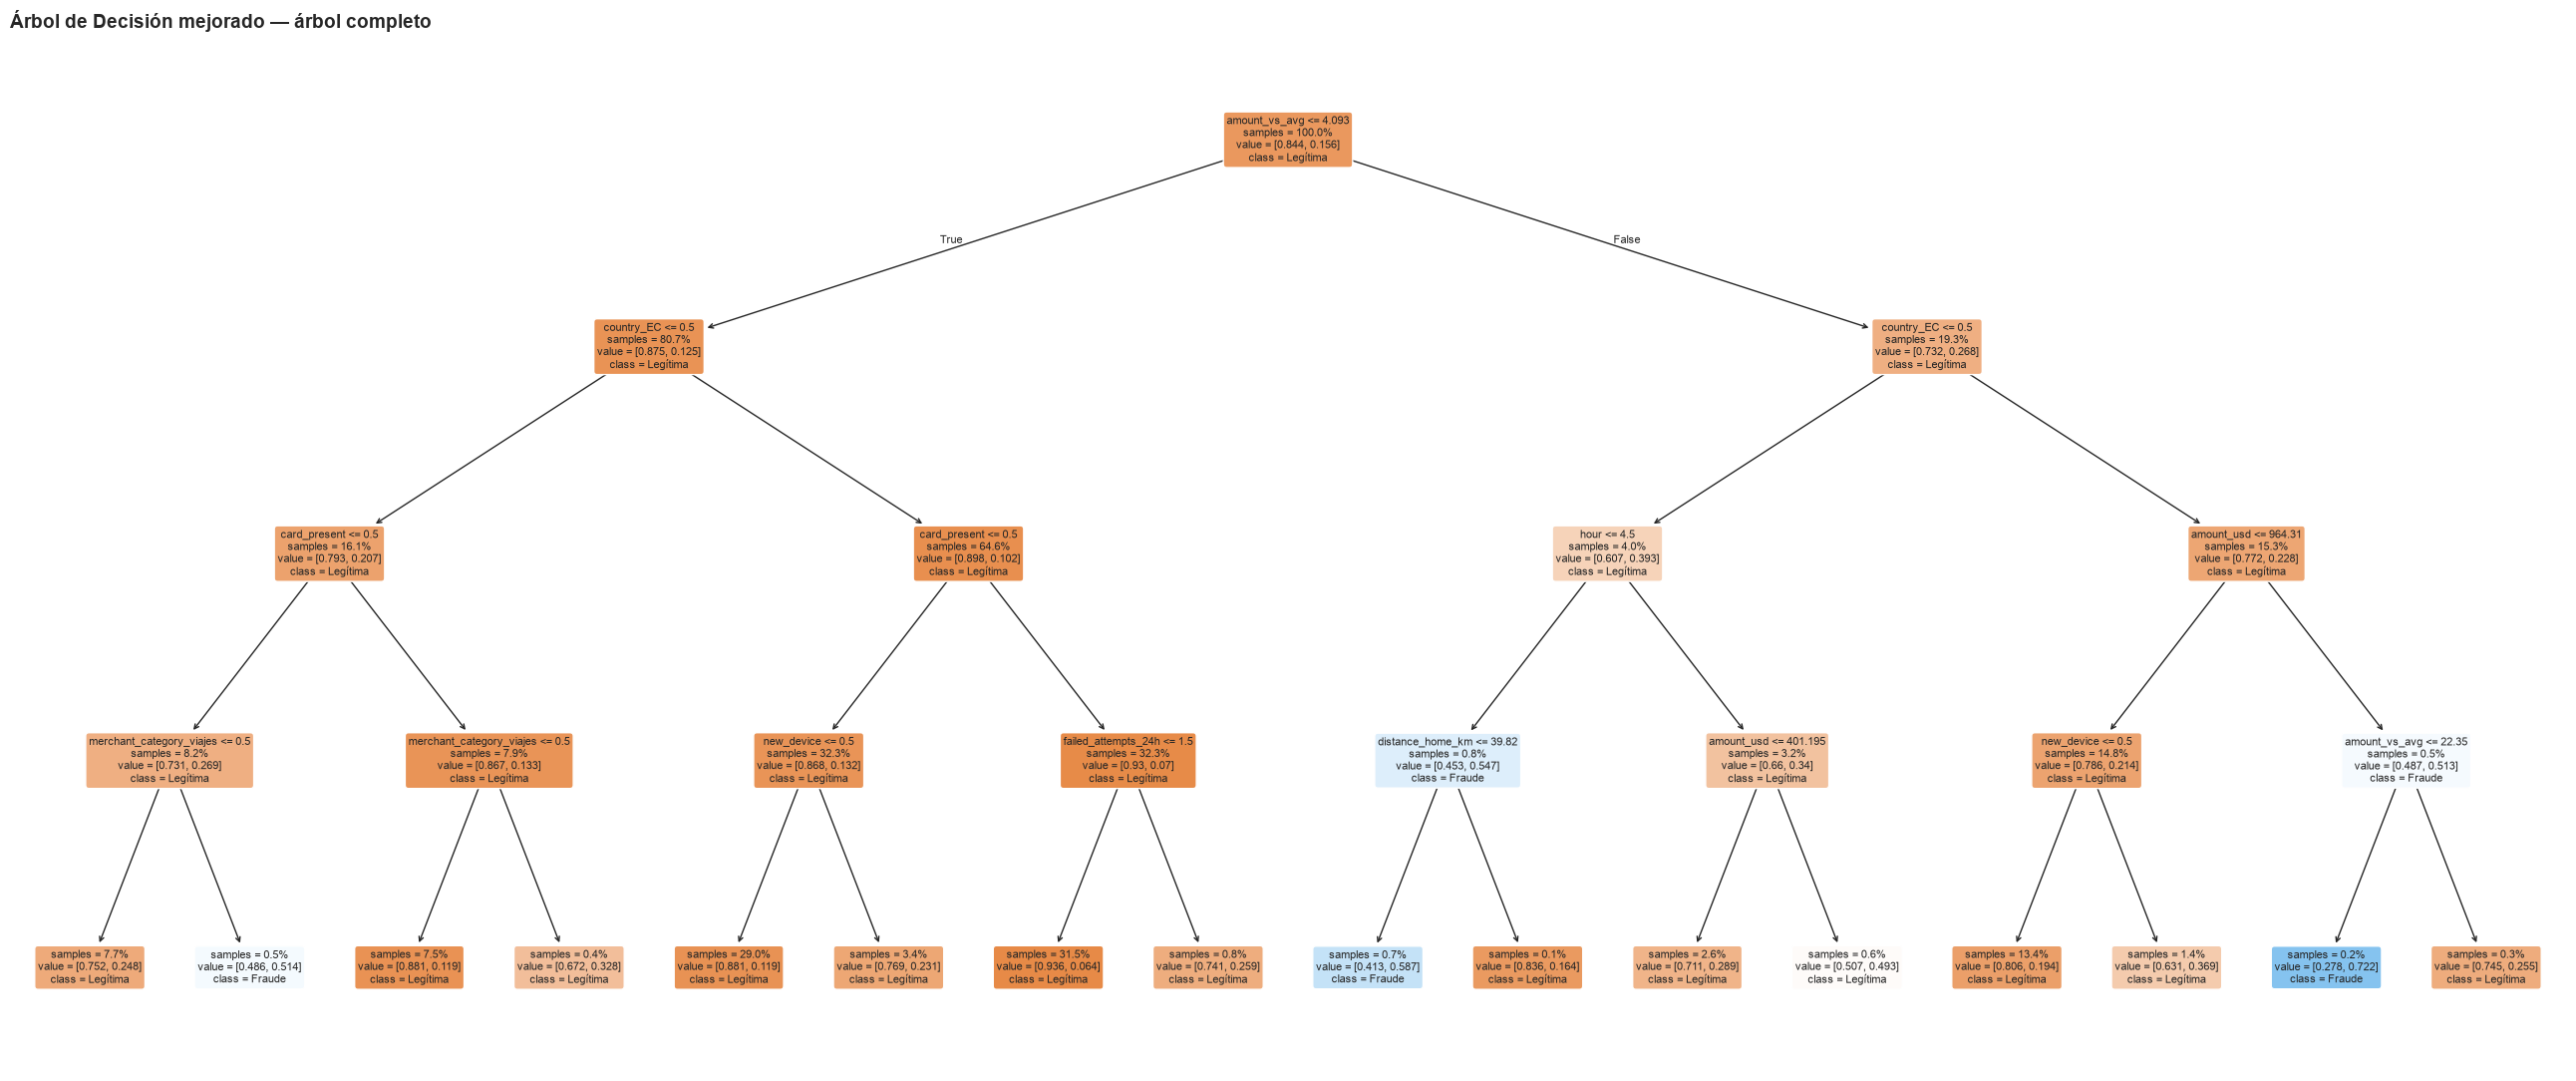

In [23]:
modelo_v2 = grid_v2.best_estimator_
fig, ax = plt.subplots(figsize=(26, 11))
plot_tree(modelo_v2.named_steps["modelo"], feature_names=modelo_v2.named_steps["prep"].get_feature_names_out(),
          class_names=["Legítima", "Fraude"], filled=True, rounded=True, impurity=False, proportion=True, fontsize=8, ax=ax)
ax.set_title("Árbol de Decisión mejorado — árbol completo", loc="left", fontsize=14, fontweight="bold")
guardar("arbol_final_reglas")

Se presentan las reglas completas del árbol mejorado en formato de texto.

In [24]:
print(export_text(modelo_v2.named_steps["modelo"],
                  feature_names=list(modelo_v2.named_steps["prep"].get_feature_names_out())))

|--- amount_vs_avg <= 4.09
|   |--- country_EC <= 0.50
|   |   |--- card_present <= 0.50
|   |   |   |--- merchant_category_viajes <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- merchant_category_viajes >  0.50
|   |   |   |   |--- class: 1
|   |   |--- card_present >  0.50
|   |   |   |--- merchant_category_viajes <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- merchant_category_viajes >  0.50
|   |   |   |   |--- class: 0
|   |--- country_EC >  0.50
|   |   |--- card_present <= 0.50
|   |   |   |--- new_device <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- new_device >  0.50
|   |   |   |   |--- class: 0
|   |   |--- card_present >  0.50
|   |   |   |--- failed_attempts_24h <= 1.50
|   |   |   |   |--- class: 0
|   |   |   |--- failed_attempts_24h >  1.50
|   |   |   |   |--- class: 0
|--- amount_vs_avg >  4.09
|   |--- country_EC <= 0.50
|   |   |--- hour <= 4.50
|   |   |   |--- distance_home_km <= 39.82
|   |   |   |   |--- class: 1
|   |   |   |--- distance

## 7. Guardado

Se guarda el árbol mejorado como final (mayor PR-AUC y menor sobreajuste que el base), ajustado en todo train, con sus métricas de CV y sus probabilidades fuera de fold.

In [25]:
guardar_resultados("arbol_decision", grid_v2.best_estimator_, resumen_cv(grid_v2), y, oof_v2)

['arbol_decision.joblib', 'cv_arbol_decision.csv', 'oof_arbol_decision.csv']

## 8. Conclusiones

- **Modelo final:** árbol mejorado (profundidad 4, hoja mínima 50, gini, peso de fraude ×10, sin poda).
- **Rendimiento en CV (media ± desviación):** PR-AUC 0.040 ± 0.005 y ROC-AUC 0.672 ± 0.024, frente a 0.035 y 0.631 del árbol base; el cociente train/validación baja de 1.81 a 1.28 (menos sobreajuste).
- **Con el umbral óptimo de F1 (0.34):** alerta el 2.8% de las transacciones con precisión del 7.9%, sensibilidad del 12.0% y F1 de 0.095 (87 fraudes detectados, 640 no detectados, 1,019 falsas alarmas).
- **Según capacidad de revisión:** revisando el 5% de mayor riesgo detecta el 17% de los fraudes con precisión del 5.8%, similar a la Regresión Logística (16.8% y 6.1%).
- **Reglas principales:** gasto por encima de 4× lo habitual (`amount_vs_avg`), país distinto de EC, tarjeta no presente, categoría viajes y madrugada; a diferencia de la Regresión Logística, el árbol sí capta el riesgo de madrugada.
- **Experimentos descartados:** poda `ccp_alpha` y criterio entropy (sin efecto), `max_leaf_nodes` (peor) y SMOTE en sus tres variantes (peor que el árbol base); el bagging de árboles fue el único que superó al árbol, lo que anticipa la ventaja de los ensambles.
- **Limitación:** con solo 78 probabilidades distintas el árbol ordena el riesgo de forma gruesa y su PR-AUC sigue por debajo de la Regresión Logística (0.051); su valor está en la interpretabilidad de las reglas.